# 1. Análise Exploratória de Dados (EDA) e Formulação de Hipóteses
**Tech Challenge — Fase 3: Predição e Inteligência Analítica para Alfabetização no Brasil**

### Objetivo desta Etapa
Compreender o comportamento dos indicadores de alfabetização nos municípios brasileiros, avaliar distribuições regionais, investigar o impacto de variáveis socioeconómicas (IBGE) e validar hipóteses estatísticas que fundamentem a engenharia de atributos (*Feature Engineering*) e a prevenção de *Data Leakage* na etapa de modelagem supervisionada.

In [15]:
#Importação das bibliotecas
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#Configurações dos gráficos
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
PALETTE = ["#e63946", "#2a9d8f"]  # 0 = Não Atingiu Meta (Vermelho) | 1 = Atingiu Meta (Verde)


PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ABT_PATH = PROJECT_DIR / "data" / "processed" / "abt_alfabetizacao_municipios.csv"
IMAGES_DIR = PROJECT_DIR / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(ABT_PATH)
print(f"Total de registos na ABT (todas as redes): {len(df_raw):,}")


Total de registos na ABT (todas as redes): 10,806


Decisão Analítica 1: Filtrar a rede MUNICIPAL (titular das metas municipais do MEC)  
Evita sobreposição/duplicidade geográfica com a rede agregada 'Pública (Estadual e Municipal)'

In [14]:
df = df_raw[df_raw["rede_key"] == "MUNICIPAL"].copy()
print(f"Total de municípios únicos analisados (Rede Municipal): {len(df):,}")
df[["id_municipio", "nome_geografia", "sigla_uf", "macrorregiao", "taxa_alfabetizacao_2023_pct", "taxa_alfabetizacao_2024_pct", "valor_meta_2024_pct", "target_atingiu_meta_2024"]].head()

Total de municípios únicos analisados (Rede Municipal): 5,232


,id_municipio,nome_geografia,sigla_uf,macrorregiao,taxa_alfabetizacao_2023_pct,taxa_alfabetizacao_2024_pct,valor_meta_2024_pct,target_atingiu_meta_2024
0,1504208,MARABA,PA,Norte,51.46,50.68,56.17,0
1,1505064,NOVO REPARTIMENTO,PA,Norte,55.60,47.88,59.65,0
4,1702000,ARAGUACU,TO,Norte,44.49,40.54,50.21,0
5,1710706,ITAGUATINS,TO,Norte,32.53,18.09,39.48,0
6,1716653,PEQUIZEIRO,TO,Norte,35.23,61.79,41.97,1


## 2. Análise das diferenças regionais
* **Hipótese 1 ($H_1$):** Existem diferenças importantes entre as regiões brasileiras tanto nos níveis iniciais de alfabetização quanto na capacidade de alcançar as metas estabelecidas pelo MEC para 2024

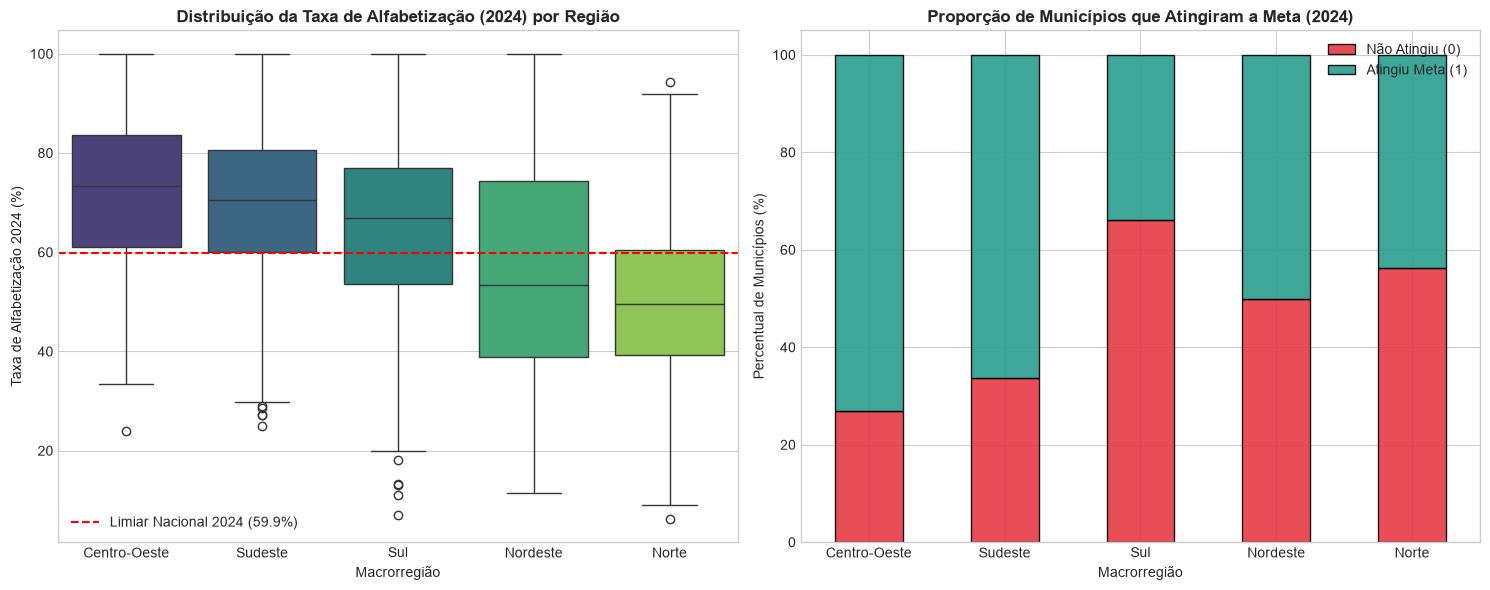

,municipios,mediana_taxa_2023,mediana_taxa_2024,pct_atingiu_meta_2024,mediana_pib_per_capita
macrorregiao,,,,,
Centro-Oeste,461,65.510,73.260,73.10,543627.0
Sudeste,1590,61.375,70.600,66.23,387928.0
Sul,1054,73.875,66.800,33.87,378529.5
Nordeste,1738,49.635,53.405,50.12,213445.0
Norte,389,46.700,49.590,43.70,358400.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

order_reg = (
    df.groupby("macrorregiao")["taxa_alfabetizacao_2024_pct"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df, x="macrorregiao", y="taxa_alfabetizacao_2024_pct",
    order=order_reg, palette="viridis", ax=axes[0]
)
axes[0].axhline(59.9, color="red", linestyle="--", label="Limiar Nacional 2024 (59.9%)")
axes[0].set_title("Distribuição da Taxa de Alfabetização (2024) por Região", fontweight="bold")
axes[0].set_xlabel("Macrorregião")
axes[0].set_ylabel("Taxa de Alfabetização 2024 (%)")
axes[0].legend()

prop_df = (
    df.groupby("macrorregiao")["target_atingiu_meta_2024"]
    .value_counts(normalize=True)
    .unstack()
    .fillna(0) * 100
).loc[order_reg]

prop_df.plot(kind="bar", stacked=True, color=PALETTE, ax=axes[1], edgecolor="black", alpha=0.9)
axes[1].set_title("Proporção de Municípios que Atingiram a Meta (2024)", fontweight="bold")
axes[1].set_xlabel("Macrorregião")
axes[1].set_ylabel("Percentual de Municípios (%)")
axes[1].legend(["Não Atingiu (0)", "Atingiu Meta (1)"], loc="upper right")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
fig.savefig(IMAGES_DIR / "01_disparidade_regional_alfabetizacao.png", dpi=300)
plt.show()

resumo_reg = df.groupby("macrorregiao").agg(
    municipios=("id_municipio", "count"),
    mediana_taxa_2023=("taxa_alfabetizacao_2023_pct", "median"),
    mediana_taxa_2024=("taxa_alfabetizacao_2024_pct", "median"),
    pct_atingiu_meta_2024=("target_atingiu_meta_2024", lambda x: round(x.mean() * 100, 2)),
    mediana_pib_per_capita=("pib_per_capita_brl", "median"),
).loc[order_reg]
display(resumo_reg)

 
Os dados mostram claramente que existem diferenças na alfabetização entre as regiões brasileiras. 
* Norte e Nordeste apresentam níveis mais baixos de alfabetização e mais dificuldade para alcançar as metas.
* Centro-Oeste e Sudeste têm resultados melhores.
* O Sul foi um caso diferente: apesar de apresentar uma taxa geral de alfabetização alta, teve um percentual menor de metas atingidas. Isso pode estar relacionado ao fato de que, por já ter índices elevados, precisa avançar ainda mais para cumprir as metas, além dos impactos das crises climáticas na região (enchente de 2024).  
  
Na prática: as políticas públicas e os modelos de previsão precisam considerar as diferenças entre as regiões para alcançar melhores resultados.

## 3. Evolução dos resultados (2023 e 2024) e esforço para alcançar a meta
* **Hipótese 2 ($H_2$):** Os resultado de 2023 influenciam os resultados de 2024 Além disso quanto maior a diferença entre a taxca de alfabetização de 2023 e a meta de 2024, mais difícil será para o municipio alcançar essa meta em curto prazo?

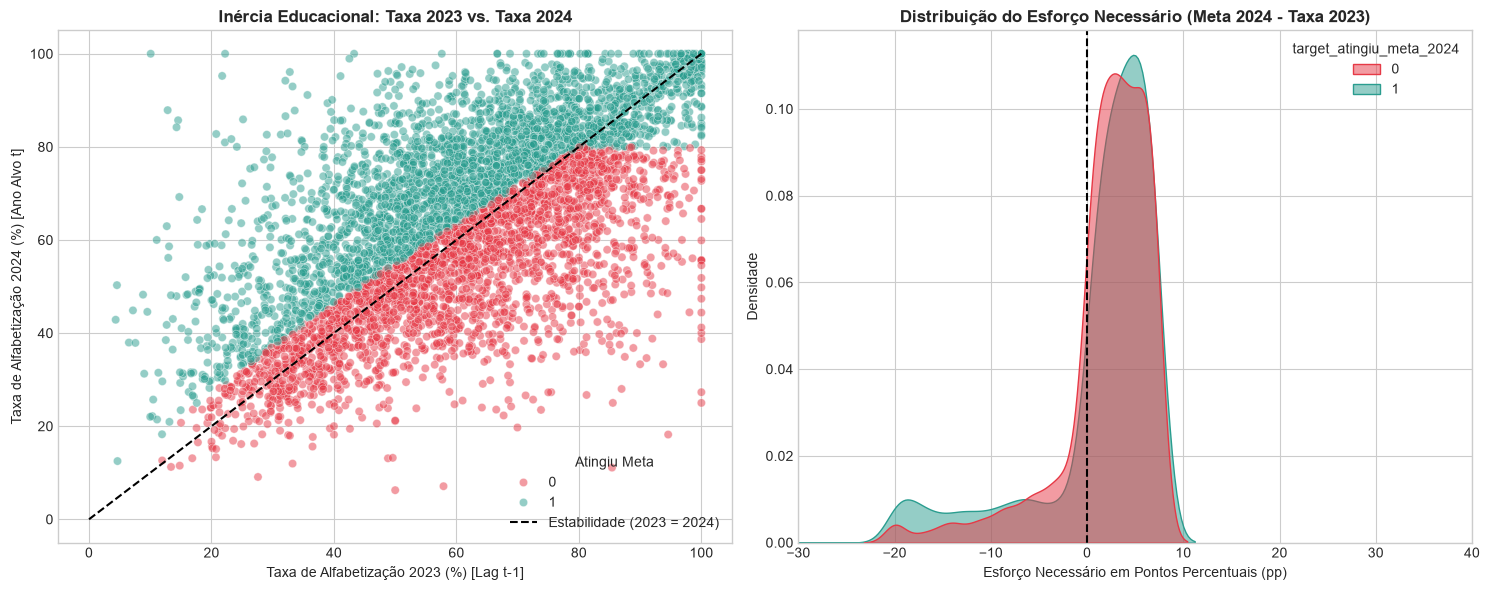

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df, x="taxa_alfabetizacao_2023_pct", y="taxa_alfabetizacao_2024_pct",
    hue="target_atingiu_meta_2024", palette=PALETTE, alpha=0.5, ax=axes[0]
)
axes[0].plot([0, 100], [0, 100], color="black", linestyle="--", label="Estabilidade (2023 = 2024)")
axes[0].set_title("Inércia Educacional: Taxa 2023 vs. Taxa 2024", fontweight="bold")
axes[0].set_xlabel("Taxa de Alfabetização 2023 (%) [Lag t-1]")
axes[0].set_ylabel("Taxa de Alfabetização 2024 (%) [Ano Alvo t]")
axes[0].legend(title="Atingiu Meta")

sns.kdeplot(
    data=df, x="esforco_necessario_meta_2024_pp", hue="target_atingiu_meta_2024",
    fill=True, palette=PALETTE, common_norm=False, alpha=0.5, ax=axes[1]
)
axes[1].axvline(0, color="black", linestyle="--", label="Meta 2024 = Resultado 2023")
axes[1].set_xlim(-30, 40)
axes[1].set_title("Distribuição do Esforço Necessário (Meta 2024 - Taxa 2023)", fontweight="bold")
axes[1].set_xlabel("Esforço Necessário em Pontos Percentuais (pp)")
axes[1].set_ylabel("Densidade")

plt.tight_layout()
fig.savefig(IMAGES_DIR / "02_inercia_e_esforco_meta.png", dpi=300)
plt.show()

Os resultados mostram que o desempenho do município em 2023 tem grande influência nos resultados de 2024. Os municípios que precisavam aumentar muito suas taxas de alfabetização para alcançar a meta foram os que tiveram mais dificuldade para atingi-la.

Na prática: o modelo precisa considerar o quanto cada município precisa melhorar para alcançar a meta, pois essa informação ajuda a identificar quais têm maior dificuldade em atingir os resultados esperados.

## 4. Fatores socioeconômicos e dificuldades de aprendizagem
* **Hipótese 3 ($H_3$):** Municípios com maior PIB per capita tendem a ter melhores condições para alcançar as metas de alfabetização. Como existem municípios com valores muito acima dos demais, o uso do logaritmo do PIB per capita pode ajudar na análise dos dados e na construção do modelo.
* **Hipótese 4 ($H_4$):** Municípios com mais alunos nos níveis mais baixos de proficiência em 2023 (níveis 0, 1 e 2) têm menor probabilidade de alcançar a meta de alfabetização em 2024.

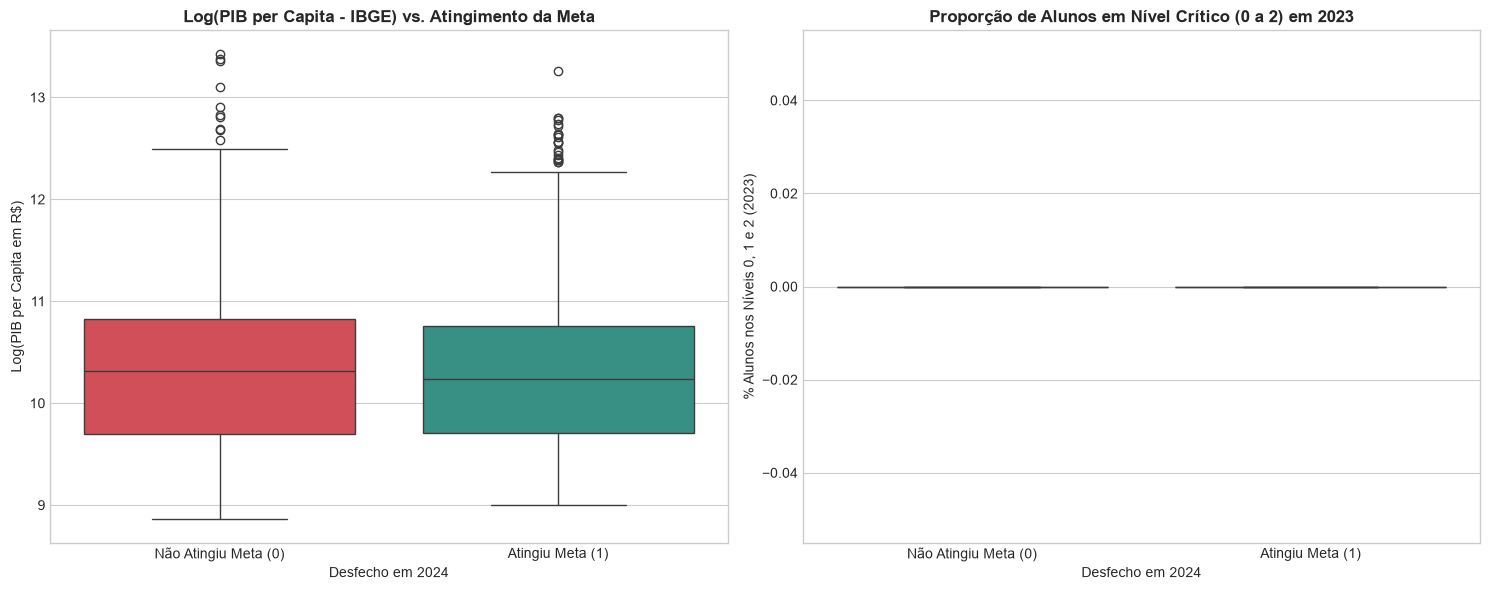

Esforço Necessário (pp)        | Mediana (Atingiu=1):       3.33 | Mediana (Não=0):       2.98 | p-valor: 1.56e-01
PIB per Capita (R$)            | Mediana (Atingiu=1):  289569.00 | Mediana (Não=0):  348883.50 | p-valor: 1.03e-07
% Baixo Nível (0-2) em 2023    | Mediana (Atingiu=1):       0.00 | Mediana (Não=0):       0.00 | p-valor: nan
Média de Português 2023        | Mediana (Atingiu=1):     749.97 | Mediana (Não=0):     749.36 | p-valor: 4.15e-02


In [18]:

# 1. Ajuste e Correção do PIB na EDA (Convertendo Mil R$ para R$ per capita e aplicando Log)
df["pib_total_mil_brl"] = df["pib_per_capita_brl"]  # Mantém a referência original do IBGE (Var 37)
df["pib_per_capita_real_brl"] = (df["pib_total_mil_brl"] * 1000.0) / df["populacao_estimada"].replace(0, np.nan)
df["log_pib_per_capita"] = np.log1p(df["pib_per_capita_real_brl"].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=df, x="target_atingiu_meta_2024", y="log_pib_per_capita", palette=PALETTE, ax=axes[0])
axes[0].set_xticklabels(["Não Atingiu Meta (0)", "Atingiu Meta (1)"])
axes[0].set_title("Log(PIB per Capita - IBGE) vs. Atingimento da Meta", fontweight="bold")
axes[0].set_xlabel("Desfecho em 2024")
axes[0].set_ylabel("Log(PIB per Capita em R$)")

sns.boxplot(data=df, x="target_atingiu_meta_2024", y="proporcao_baixo_nivel_2023_pct", palette=PALETTE, ax=axes[1])
axes[1].set_xticklabels(["Não Atingiu Meta (0)", "Atingiu Meta (1)"])
axes[1].set_title("Proporção de Alunos em Nível Crítico (0 a 2) em 2023", fontweight="bold")
axes[1].set_xlabel("Desfecho em 2024")
axes[1].set_ylabel("% Alunos nos Níveis 0, 1 e 2 (2023)")

plt.tight_layout()
fig.savefig(IMAGES_DIR / "03_impacto_socioeconomico_e_vulnerabilidade.png", dpi=300)
plt.show()

# Validação estatística não-paramétrica (Mann-Whitney U)
g1 = df[df["target_atingiu_meta_2024"] == 1]
g0 = df[df["target_atingiu_meta_2024"] == 0]

for col, nome in [
    ("esforco_necessario_meta_2024_pp", "Esforço Necessário (pp)"),
    ("pib_per_capita_brl", "PIB per Capita (R$)"),
    ("proporcao_baixo_nivel_2023_pct", "% Baixo Nível (0-2) em 2023"),
    ("media_portugues_2023", "Média de Português 2023"),
]:
    stat, p_val = stats.mannwhitneyu(g1[col].dropna(), g0[col].dropna())
    print(f"{nome:30s} | Mediana (Atingiu=1): {g1[col].median():10.2f} | Mediana (Não=0): {g0[col].median():10.2f} | p-valor: {p_val:.2e}")

Os dados mostram que ter um PIB per capita alto não garante melhores resultados na alfabetização. Alguns municípios com maior riqueza não conseguiram atingir suas metas, enquanto outros, com menos recursos, conseguiram alcançar bons resultados.

Na prática: ter recursos financeiros é importante, mas também é necessário saber como utilizá-los. A gestão pedagógica e a aplicação dos recursos de forma adequada podem fazer diferença nos resultados da alfabetização.

Ponto importante  

Durante a análise, identificamos um problema importante: a base de dados de 2023 não continha informações detalhadas sobre os níveis de proficiência dos alunos. Essa limitação foi importante para o projeto, pois evitou o uso de dados incompletos ou inconsistentes e ajudou a prevenir possíveis problemas de vazamento de dados (data leakage).

## 5. Matriz de Correlação e Decisões para a Pipeline de Machine Learning
A matriz de correlação abaixo orienta diretamente a construção da pipeline no `scikit-learn`:
1. **1. Evitar o vazamento de dados (data leakage): as variáveis de 2024, como a taxa de alfabetização, a média de Português e a participação dos alunos, não devem ser usadas como preditoras, pois contêm informações do mesmo período que queremos prever.**
2. **Preparar as variáveis para o modelo (feature engineering):**
   * Aplicar a transformação logarítmica ao PIB per capita e à população estimada para reduzir as diferenças muito grandes entre seus valores.
   * Incluir a variável esforco_necessario_meta_2024_pp, que indica quanto o município precisa melhorar para alcançar a meta.
   * Incluir a variável proporcao_baixo_nivel_2023_pct, que representa a proporção de alunos com baixo nível de proficiência em 2023.

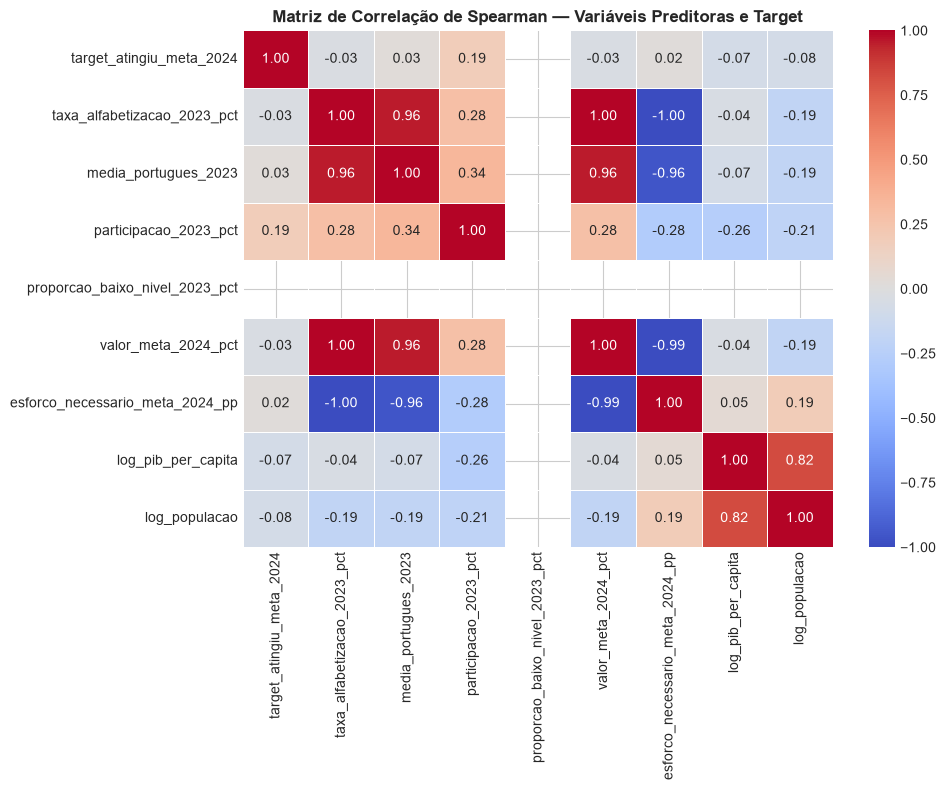

In [5]:
cols_corr = [
    "target_atingiu_meta_2024",
    "taxa_alfabetizacao_2023_pct",
    "media_portugues_2023",
    "participacao_2023_pct",
    "proporcao_baixo_nivel_2023_pct",
    "valor_meta_2024_pct",
    "esforco_necessario_meta_2024_pp",
    "log_pib_per_capita",
    "log_populacao",
]
corr_matrix = df[cols_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5, ax=ax)
ax.set_title("Matriz de Correlação de Spearman — Variáveis Preditoras e Target", fontweight="bold")
plt.tight_layout()
fig.savefig(IMAGES_DIR / "04_matriz_correlacao_features.png", dpi=300)
plt.show()